---
**Script name:** 06_bat_data_metric_extraction.ipynb

**Purpose of script:** This script is to extract metrics of bat activitiy from the cleaned data. 

**Author:** Dr Katie Allan

**Date Created:** 2023-02-25

**Email:** katie.allan@sussex.ac.uk

**License:** 

---

**Notes:** Ensure folder paths are set properly.

---

## Import libraries that are required

In [1]:
import time
from datetime import timedelta
import sqlalchemy as psql
import pickle
import pandas as pd
import numpy as np
import os
from plotnine import (
    ggplot,
    aes,
    geom_histogram,
    geom_point,
    geom_line,
    geom_smooth,
    after_stat,
    geom_line,
    geom_bar,
    coord_flip,
    facet_wrap,
    labs,
    scale_y_datetime,
    scale_y_discrete,
    theme_bw,
    scale_y_continuous,
    element_text,
    theme
)

## Load Data

In [ ]:
#load csvs of data
bat_data = pd.read_csv('output/bat_data_filtered_classification_joined_reduced_nighttime.csv')
sun_data = pd.read_csv('data/sun_data.csv')
bat_tag_data = pd.read_csv('output/bat_tags.csv')

## Data processing

In [3]:
#remove points that are not to be included in window
bat_data = bat_data.loc[bat_data['window_period'].isnull()]
bat_data

,radio_id,tag_id,node_id,tag_rssi,validated,time,station_id,method,data_size,median_error_seconds,...,max_rssi,n_receivers,activity_class,rec_type,window_period,sunrise,sunset,daytime_detection,bat_day,next_bat_day
0,5,33663378,3781a5,-107.0,0,2023-11-10 18:54:13+00:00,None,kl_div,29837.0,123.0,...,NaN,NaN,none,Node,None,07:25:07,16:34:13,0,NaT,NaT
1,5,33663378,3781a5,-109.0,0,2023-11-10 18:54:23+00:00,None,kl_div,29837.0,123.0,...,NaN,NaN,none,Node,None,07:25:07,16:34:13,0,NaT,NaT
2,5,33663378,3781a5,-106.0,0,2023-11-10 18:54:33+00:00,None,kl_div,29837.0,123.0,...,NaN,NaN,none,Node,None,07:25:07,16:34:13,0,NaT,NaT
3,5,33663378,3781a5,-109.0,0,2023-11-10 18:54:53+00:00,None,kl_div,29837.0,123.0,...,NaN,NaN,none,Node,None,07:25:07,16:34:13,0,NaT,NaT
4,5,33663378,328787,-108.0,0,2023-11-10 18:56:44+00:00,None,kl_div,7509.0,123.0,...,NaN,NaN,none,Node,None,07:25:07,16:34:13,0,NaT,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144373,1,2A615252,None,-108.0,0,2023-12-31 00:42:52+00:00,31D096AEC921,ctt,NaN,NaN,...,-88.0,1.0,active,Station,None,08:21:13,16:15:31,0,NaT,NaT
144374,1,2A615252,None,-103.0,0,2023-12-31 00:43:02+00:00,31D096AEC921,ctt,NaN,NaN,...,-103.0,1.0,active,Station,None,08:21:13,16:15:31,0,NaT,NaT
144375,1,2A615252,None,-96.0,0,2023-12-31 00:45:09+00:00,31D096AEC921,ctt,NaN,NaN,...,-96.0,1.0,active,Station,None,08:21:13,16:15:31,0,NaT,NaT
144376,1,2A615252,None,-99.0,0,2023-12-31 00:45:19+00:00,31D096AEC921,ctt,NaN,NaN,...,-96.0,1.0,active,Station,None,08:21:13,16:15:31,0,NaT,NaT


In [4]:
#remove columns and recreate with sundata
bat_data = bat_data.drop(columns=["validated", "software", "max_rssi", "window_period", "sunrise", "sunset", "daytime_detection", "bat_day", "next_bat_day"])
bat_data

,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,median_error_seconds,max_error_seconds,...,location,bat_name,ring_no,capture_site,Date,daytime,week,n_receivers,activity_class,rec_type
0,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,None,kl_div,29837.0,123.0,565.0,...,Winstow Cottages,Andrea,BA0319,chudleigh_rock,2023-11-10,18:54:13,45,NaN,none,Node
1,5,33663378,3781a5,-109.0,2023-11-10 18:54:23+00:00,None,kl_div,29837.0,123.0,565.0,...,Winstow Cottages,Andrea,BA0319,chudleigh_rock,2023-11-10,18:54:23,45,NaN,none,Node
2,5,33663378,3781a5,-106.0,2023-11-10 18:54:33+00:00,None,kl_div,29837.0,123.0,565.0,...,Winstow Cottages,Andrea,BA0319,chudleigh_rock,2023-11-10,18:54:33,45,NaN,none,Node
3,5,33663378,3781a5,-109.0,2023-11-10 18:54:53+00:00,None,kl_div,29837.0,123.0,565.0,...,Winstow Cottages,Andrea,BA0319,chudleigh_rock,2023-11-10,18:54:53,45,NaN,none,Node
4,5,33663378,328787,-108.0,2023-11-10 18:56:44+00:00,None,kl_div,7509.0,123.0,565.0,...,Lawell House,Andrea,BA0319,chudleigh_rock,2023-11-10,18:56:44,45,NaN,none,Node
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144373,1,2A615252,None,-108.0,2023-12-31 00:42:52+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,Palace Meadow,Zac,BA0318,chudleigh_rock,2023-12-31,00:42:52,52,1.0,active,Station
144374,1,2A615252,None,-103.0,2023-12-31 00:43:02+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,Palace Meadow,Zac,BA0318,chudleigh_rock,2023-12-31,00:43:02,52,1.0,active,Station
144375,1,2A615252,None,-96.0,2023-12-31 00:45:09+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,Palace Meadow,Zac,BA0318,chudleigh_rock,2023-12-31,00:45:09,52,1.0,active,Station
144376,1,2A615252,None,-99.0,2023-12-31 00:45:19+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,Palace Meadow,Zac,BA0318,chudleigh_rock,2023-12-31,00:45:19,52,1.0,active,Station


In [5]:
# remove any duplicate rows from dataframe
bat_data = bat_data.drop_duplicates()
sun_data = sun_data.drop_duplicates()
bat_tag_data = bat_tag_data.drop_duplicates()

In [6]:
#create next date columns
sun_data['Next_Date'] = sun_data['Date'] + pd.Timedelta(days=1)
#select sunrise values
sunrise_values = sun_data[['Date', 'sunriseEnd']]
#keep only suynset values
sun_data = sun_data[['Date', 'Next_Date', 'sunsetStart']]
#join into one dataframe
sun_data = pd.merge(left = sun_data,
                    right = sunrise_values,
                    how = 'left',
                    left_on = 'Next_Date',
                    right_on = 'Date')
#rename column
sun_data = sun_data.rename(columns={'Date_x': 'Date'})
#keep needed ones
sun_data = sun_data = sun_data[['Date', 'Next_Date', 'sunsetStart', 'sunriseEnd']]
sun_data

,Date,Next_Date,sunsetStart,sunriseEnd
0,2021-09-13,2021-09-14,2021-09-13 18:31:57+00:00,2021-09-14 05:53:11+00:00
1,2021-09-14,2021-09-15,2021-09-14 18:29:42+00:00,2021-09-15 05:54:41+00:00
2,2021-09-15,2021-09-16,2021-09-15 18:27:27+00:00,2021-09-16 05:56:12+00:00
3,2021-09-16,2021-09-17,2021-09-16 18:25:12+00:00,2021-09-17 05:57:44+00:00
4,2021-09-17,2021-09-18,2021-09-17 18:22:57+00:00,2021-09-18 05:59:15+00:00
...,...,...,...,...
860,2024-01-21,2024-01-22,2024-01-21 16:43:31+00:00,2024-01-22 08:08:46+00:00
861,2024-01-22,2024-01-23,2024-01-22 16:45:09+00:00,2024-01-23 08:07:39+00:00
862,2024-01-23,2024-01-24,2024-01-23 16:46:49+00:00,2024-01-24 08:06:31+00:00
863,2024-01-24,2024-01-25,2024-01-24 16:48:30+00:00,2024-01-25 08:05:20+00:00


In [7]:
#Merge sunrise and sunset columns to bat data by Date
bat_data = pd.merge(left = bat_data,
                    right = sun_data,
                    how = 'left',
                    left_on = 'Date',
                    right_on = 'Date')
bat_data

,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,median_error_seconds,max_error_seconds,...,capture_site,Date,daytime,week,n_receivers,activity_class,rec_type,Next_Date,sunsetStart,sunriseEnd
0,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,None,kl_div,29837.0,123.0,565.0,...,chudleigh_rock,2023-11-10,18:54:13,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00
1,5,33663378,3781a5,-109.0,2023-11-10 18:54:23+00:00,None,kl_div,29837.0,123.0,565.0,...,chudleigh_rock,2023-11-10,18:54:23,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00
2,5,33663378,3781a5,-106.0,2023-11-10 18:54:33+00:00,None,kl_div,29837.0,123.0,565.0,...,chudleigh_rock,2023-11-10,18:54:33,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00
3,5,33663378,3781a5,-109.0,2023-11-10 18:54:53+00:00,None,kl_div,29837.0,123.0,565.0,...,chudleigh_rock,2023-11-10,18:54:53,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00
4,5,33663378,328787,-108.0,2023-11-10 18:56:44+00:00,None,kl_div,7509.0,123.0,565.0,...,chudleigh_rock,2023-11-10,18:56:44,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144373,1,2A615252,None,-108.0,2023-12-31 00:42:52+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,chudleigh_rock,2023-12-31,00:42:52,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00
144374,1,2A615252,None,-103.0,2023-12-31 00:43:02+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,chudleigh_rock,2023-12-31,00:43:02,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00
144375,1,2A615252,None,-96.0,2023-12-31 00:45:09+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,chudleigh_rock,2023-12-31,00:45:09,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00
144376,1,2A615252,None,-99.0,2023-12-31 00:45:19+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,chudleigh_rock,2023-12-31,00:45:19,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00


In [8]:
# create bat_day column
bat_data['bat_day'] = np.where(
    (bat_data['time'] <= bat_data['sunriseEnd']) & (bat_data['time'] >= bat_data['sunsetStart']),
    bat_data['Date'],
    bat_data['Date'] - pd.Timedelta(days=1)
)
bat_data

,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,median_error_seconds,max_error_seconds,...,Date,daytime,week,n_receivers,activity_class,rec_type,Next_Date,sunsetStart,sunriseEnd,bat_day
0,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,None,kl_div,29837.0,123.0,565.0,...,2023-11-10,18:54:13,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
1,5,33663378,3781a5,-109.0,2023-11-10 18:54:23+00:00,None,kl_div,29837.0,123.0,565.0,...,2023-11-10,18:54:23,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
2,5,33663378,3781a5,-106.0,2023-11-10 18:54:33+00:00,None,kl_div,29837.0,123.0,565.0,...,2023-11-10,18:54:33,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
3,5,33663378,3781a5,-109.0,2023-11-10 18:54:53+00:00,None,kl_div,29837.0,123.0,565.0,...,2023-11-10,18:54:53,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
4,5,33663378,328787,-108.0,2023-11-10 18:56:44+00:00,None,kl_div,7509.0,123.0,565.0,...,2023-11-10,18:56:44,45,NaN,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144373,1,2A615252,None,-108.0,2023-12-31 00:42:52+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,2023-12-31,00:42:52,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00,2023-12-30
144374,1,2A615252,None,-103.0,2023-12-31 00:43:02+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,2023-12-31,00:43:02,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00,2023-12-30
144375,1,2A615252,None,-96.0,2023-12-31 00:45:09+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,2023-12-31,00:45:09,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00,2023-12-30
144376,1,2A615252,None,-99.0,2023-12-31 00:45:19+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,2023-12-31,00:45:19,52,1.0,active,Station,2024-01-01,2023-12-31 16:15:31+00:00,2024-01-01 08:21:12+00:00,2023-12-30


In [9]:
#drop suninfo columns
bat_data = bat_data.drop(['Date', 'Next_Date', 'sunsetStart', 'sunriseEnd'], axis=1)

In [10]:
#join into one dataframe
bat_data = pd.merge(left = bat_data,
                    right = sun_data,
                    how = 'left',
                    left_on = 'bat_day',
                    right_on = 'Date')
#rename column
bat_data = bat_data.rename(columns={'Next_Date': 'bat_day_next'})
#remove date column
bat_data = bat_data.drop(['Date'], axis=1)
#create date column based on actual time
bat_data['Date'] =  pd.to_datetime(bat_data['time'].dt.date, format='%Y-%m-%d', errors='coerce')
bat_data

,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,median_error_seconds,max_error_seconds,...,daytime,week,n_receivers,activity_class,rec_type,bat_day,bat_day_next,sunsetStart,sunriseEnd,Date
0,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,None,kl_div,29837.0,123.0,565.0,...,18:54:13,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
1,5,33663378,3781a5,-109.0,2023-11-10 18:54:23+00:00,None,kl_div,29837.0,123.0,565.0,...,18:54:23,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
2,5,33663378,3781a5,-106.0,2023-11-10 18:54:33+00:00,None,kl_div,29837.0,123.0,565.0,...,18:54:33,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
3,5,33663378,3781a5,-109.0,2023-11-10 18:54:53+00:00,None,kl_div,29837.0,123.0,565.0,...,18:54:53,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
4,5,33663378,328787,-108.0,2023-11-10 18:56:44+00:00,None,kl_div,7509.0,123.0,565.0,...,18:56:44,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144373,1,2A615252,None,-108.0,2023-12-31 00:42:52+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,00:42:52,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31
144374,1,2A615252,None,-103.0,2023-12-31 00:43:02+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,00:43:02,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31
144375,1,2A615252,None,-96.0,2023-12-31 00:45:09+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,00:45:09,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31
144376,1,2A615252,None,-99.0,2023-12-31 00:45:19+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,00:45:19,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31


## Calculate activity metrics

In [11]:
# select first and last detection for each bat on each day
first_detection = bat_data.sort_values('time').groupby(['bat_name', 'bat_day']).first().reset_index(drop=False)
last_detection = bat_data.sort_values('time').groupby(['bat_name', 'bat_day']).last().reset_index(drop=False)

In [12]:
#join into one dataframe for total activity
total_activity = pd.merge(left = first_detection,
                          right = last_detection[['bat_name', 'bat_day', 'time']],
                          how = 'left',
                          left_on = ['bat_name', 'bat_day'],
                          right_on = ['bat_name', 'bat_day'])
#rename columns
total_activity = total_activity.rename(columns={'time_x': 'emergence_time', 'time_y': 'reentry_time'})
#calculate the total activity
total_activity['total_activity'] = total_activity["reentry_time"] - total_activity["emergence_time"]
total_activity

,bat_name,bat_day,radio_id,tag_id,node_id,tag_rssi,emergence_time,station_id,method,data_size,...,week,n_receivers,activity_class,rec_type,bat_day_next,sunsetStart,sunriseEnd,Date,reentry_time,total_activity
0,Andrea,2023-11-10,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,CFF730D7207F,kl_div,29837.0,...,45,1.0,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 20:50:11+00:00,0 days 01:55:58
1,Andrea,2023-11-11,5,33663378,376a2b,-100.0,2023-11-11 19:11:48+00:00,V30B0154C8C9,ctt,3961.0,...,45,1.0,active,Node,2023-11-12,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,2023-11-11,2023-11-11 19:40:37+00:00,0 days 00:28:49
2,Andrea,2023-11-12,5,33663378,328787,-104.0,2023-11-12 17:41:47+00:00,CFF730D7207F,kl_div,7509.0,...,45,1.0,none,Node,2023-11-13,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,2023-11-12,2023-11-12 23:16:29+00:00,0 days 05:34:42
3,Andrea,2023-11-13,5,33663378,3289f3,-110.0,2023-11-13 17:04:03+00:00,V30B0154C8C9,kl_div,3961.0,...,46,1.0,none,Node,2023-11-14,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,2023-11-13,2023-11-14 05:38:35+00:00,0 days 12:34:32
4,Andrea,2023-11-14,5,33663378,376a2b,-109.0,2023-11-14 16:58:56+00:00,V30B0154C8C9,ctt,24030.0,...,46,1.0,none,Node,2023-11-15,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,2023-11-14,2023-11-15 06:11:10+00:00,0 days 13:12:14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,4,2A615252,379f1a,-105.0,2023-12-10 17:48:05+00:00,V30B0154C8C9,ctt,2886.0,...,49,1.0,none,Station,2023-12-11,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,2023-12-10,2023-12-11 06:45:58+00:00,0 days 12:57:53
757,Zac,2023-12-24,5,2A615252,328787,-109.0,2023-12-24 16:39:57+00:00,CFF730D7207F,kl_div,1751.0,...,51,1.0,active,Node,2023-12-25,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,2023-12-24,2023-12-25 02:08:48+00:00,0 days 09:28:51
758,Zac,2023-12-26,5,2A615252,3750b3,-110.0,2023-12-26 17:29:15+00:00,V30B0154C8C9,ctt,2886.0,...,52,1.0,none,Node,2023-12-27,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,2023-12-26,2023-12-26 20:29:38+00:00,0 days 03:00:23
759,Zac,2023-12-29,5,2A615252,3781a5,-108.0,2023-12-29 17:08:44+00:00,31D096AEC921,kl_div,2859.0,...,52,1.0,none,Node,2023-12-30,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,2023-12-29,2023-12-30 06:19:32+00:00,0 days 13:10:48


In [13]:
#create total activity columns in seconds and minutes
total_activity["total_activity_seconds"] = total_activity["total_activity"].dt.total_seconds()
#if only one detection make 10 seconds (pulse rate)
total_activity.loc[total_activity['total_activity_seconds'] == 0, 'total_activity_seconds'] = 10
total_activity["total_activity_minutes"] = total_activity["total_activity_seconds"].div(60)
total_activity

,bat_name,bat_day,radio_id,tag_id,node_id,tag_rssi,emergence_time,station_id,method,data_size,...,activity_class,rec_type,bat_day_next,sunsetStart,sunriseEnd,Date,reentry_time,total_activity,total_activity_seconds,total_activity_minutes
0,Andrea,2023-11-10,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,CFF730D7207F,kl_div,29837.0,...,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 20:50:11+00:00,0 days 01:55:58,6958.0,115.966667
1,Andrea,2023-11-11,5,33663378,376a2b,-100.0,2023-11-11 19:11:48+00:00,V30B0154C8C9,ctt,3961.0,...,active,Node,2023-11-12,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,2023-11-11,2023-11-11 19:40:37+00:00,0 days 00:28:49,1729.0,28.816667
2,Andrea,2023-11-12,5,33663378,328787,-104.0,2023-11-12 17:41:47+00:00,CFF730D7207F,kl_div,7509.0,...,none,Node,2023-11-13,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,2023-11-12,2023-11-12 23:16:29+00:00,0 days 05:34:42,20082.0,334.700000
3,Andrea,2023-11-13,5,33663378,3289f3,-110.0,2023-11-13 17:04:03+00:00,V30B0154C8C9,kl_div,3961.0,...,none,Node,2023-11-14,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,2023-11-13,2023-11-14 05:38:35+00:00,0 days 12:34:32,45272.0,754.533333
4,Andrea,2023-11-14,5,33663378,376a2b,-109.0,2023-11-14 16:58:56+00:00,V30B0154C8C9,ctt,24030.0,...,none,Node,2023-11-15,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,2023-11-14,2023-11-15 06:11:10+00:00,0 days 13:12:14,47534.0,792.233333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,4,2A615252,379f1a,-105.0,2023-12-10 17:48:05+00:00,V30B0154C8C9,ctt,2886.0,...,none,Station,2023-12-11,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,2023-12-10,2023-12-11 06:45:58+00:00,0 days 12:57:53,46673.0,777.883333
757,Zac,2023-12-24,5,2A615252,328787,-109.0,2023-12-24 16:39:57+00:00,CFF730D7207F,kl_div,1751.0,...,active,Node,2023-12-25,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,2023-12-24,2023-12-25 02:08:48+00:00,0 days 09:28:51,34131.0,568.850000
758,Zac,2023-12-26,5,2A615252,3750b3,-110.0,2023-12-26 17:29:15+00:00,V30B0154C8C9,ctt,2886.0,...,none,Node,2023-12-27,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,2023-12-26,2023-12-26 20:29:38+00:00,0 days 03:00:23,10823.0,180.383333
759,Zac,2023-12-29,5,2A615252,3781a5,-108.0,2023-12-29 17:08:44+00:00,31D096AEC921,kl_div,2859.0,...,none,Node,2023-12-30,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,2023-12-29,2023-12-30 06:19:32+00:00,0 days 13:10:48,47448.0,790.800000


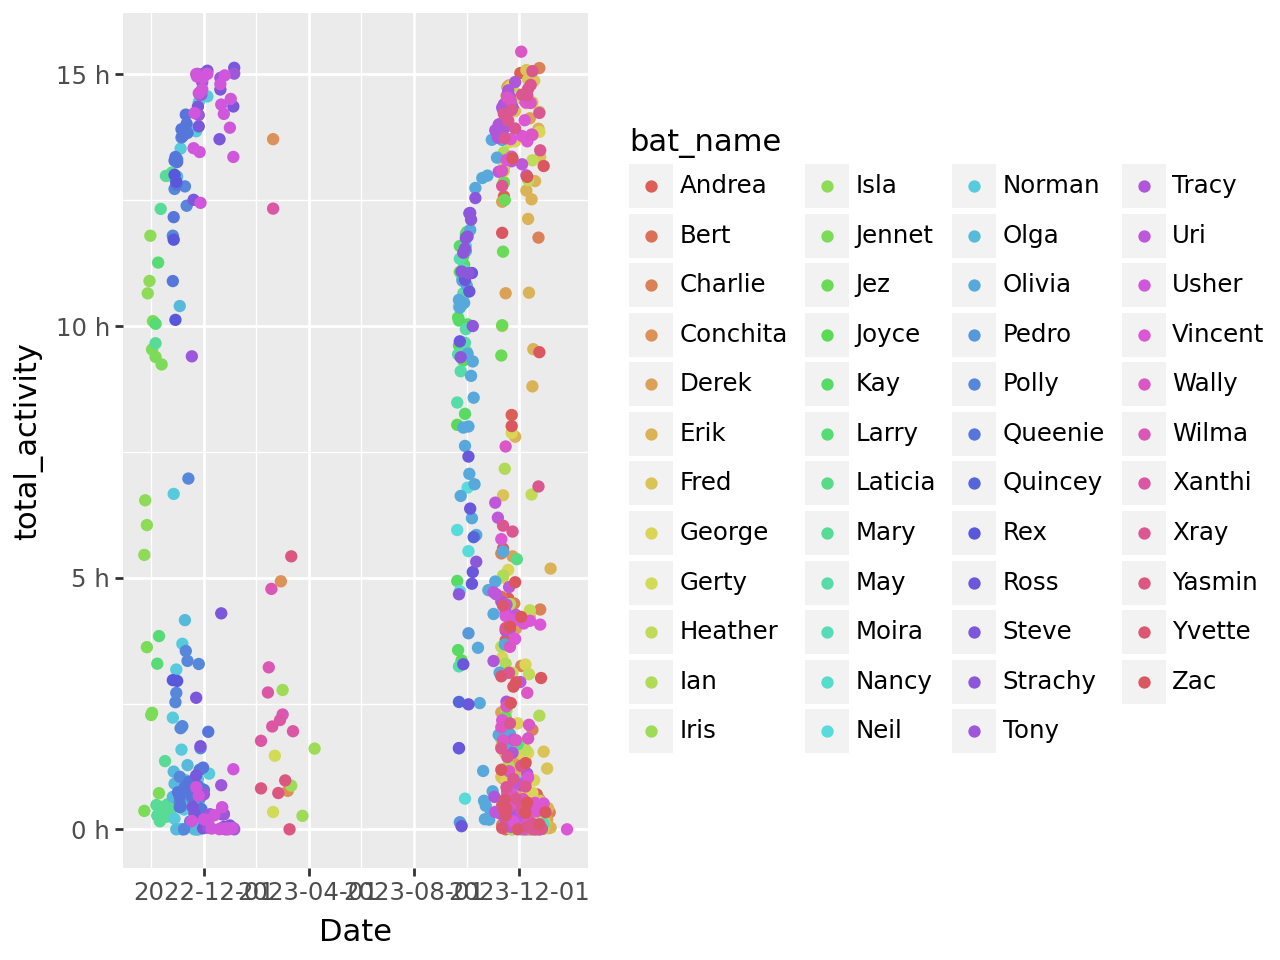

In [14]:
(
    ggplot(total_activity, aes(x="Date", y="total_activity", colour="bat_name"))
    + geom_point()
)

C:\Users\allan\anaconda3\envs\bat_analysis\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 7'. Pick better value with 'binwidth'.


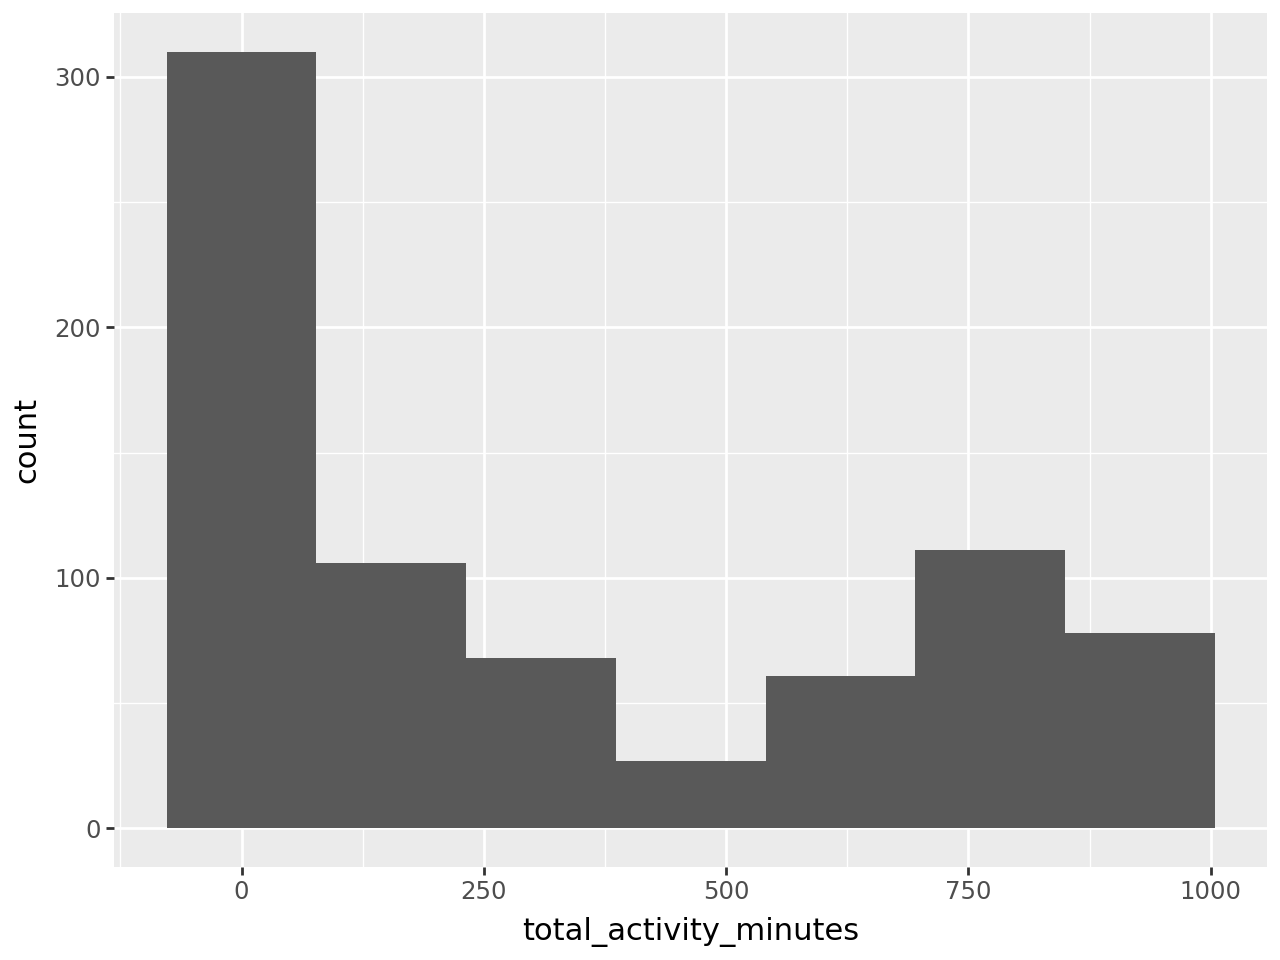

In [15]:
(
    ggplot(total_activity, aes(x="total_activity_minutes"))
    + geom_histogram()
)

In [16]:
# calculate the time since first detection in minutes
first_detection["emergence_time"] = first_detection["time"] - first_detection["sunsetStart"]
first_detection["emergence_time_minutes"] = first_detection["emergence_time"].dt.total_seconds().div(60)
first_detection

,bat_name,bat_day,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,...,week,n_receivers,activity_class,rec_type,bat_day_next,sunsetStart,sunriseEnd,Date,emergence_time,emergence_time_minutes
0,Andrea,2023-11-10,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,CFF730D7207F,kl_div,29837.0,...,45,1.0,none,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,0 days 02:20:00,140.000000
1,Andrea,2023-11-11,5,33663378,376a2b,-100.0,2023-11-11 19:11:48+00:00,V30B0154C8C9,ctt,3961.0,...,45,1.0,active,Node,2023-11-12,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,2023-11-11,0 days 02:39:04,159.066667
2,Andrea,2023-11-12,5,33663378,328787,-104.0,2023-11-12 17:41:47+00:00,CFF730D7207F,kl_div,7509.0,...,45,1.0,none,Node,2023-11-13,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,2023-11-12,0 days 01:10:31,70.516667
3,Andrea,2023-11-13,5,33663378,3289f3,-110.0,2023-11-13 17:04:03+00:00,V30B0154C8C9,kl_div,3961.0,...,46,1.0,none,Node,2023-11-14,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,2023-11-13,0 days 00:34:12,34.200000
4,Andrea,2023-11-14,5,33663378,376a2b,-109.0,2023-11-14 16:58:56+00:00,V30B0154C8C9,ctt,24030.0,...,46,1.0,none,Node,2023-11-15,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,2023-11-14,0 days 00:30:28,30.466667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,4,2A615252,379f1a,-105.0,2023-12-10 17:48:05+00:00,V30B0154C8C9,ctt,2886.0,...,49,1.0,none,Station,2023-12-11,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,2023-12-10,0 days 01:40:49,100.816667
757,Zac,2023-12-24,5,2A615252,328787,-109.0,2023-12-24 16:39:57+00:00,CFF730D7207F,kl_div,1751.0,...,51,1.0,active,Node,2023-12-25,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,2023-12-24,0 days 00:29:47,29.783333
758,Zac,2023-12-26,5,2A615252,3750b3,-110.0,2023-12-26 17:29:15+00:00,V30B0154C8C9,ctt,2886.0,...,52,1.0,none,Node,2023-12-27,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,2023-12-26,0 days 01:17:48,77.800000
759,Zac,2023-12-29,5,2A615252,3781a5,-108.0,2023-12-29 17:08:44+00:00,31D096AEC921,kl_div,2859.0,...,52,1.0,none,Node,2023-12-30,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,2023-12-29,0 days 00:55:00,55.000000


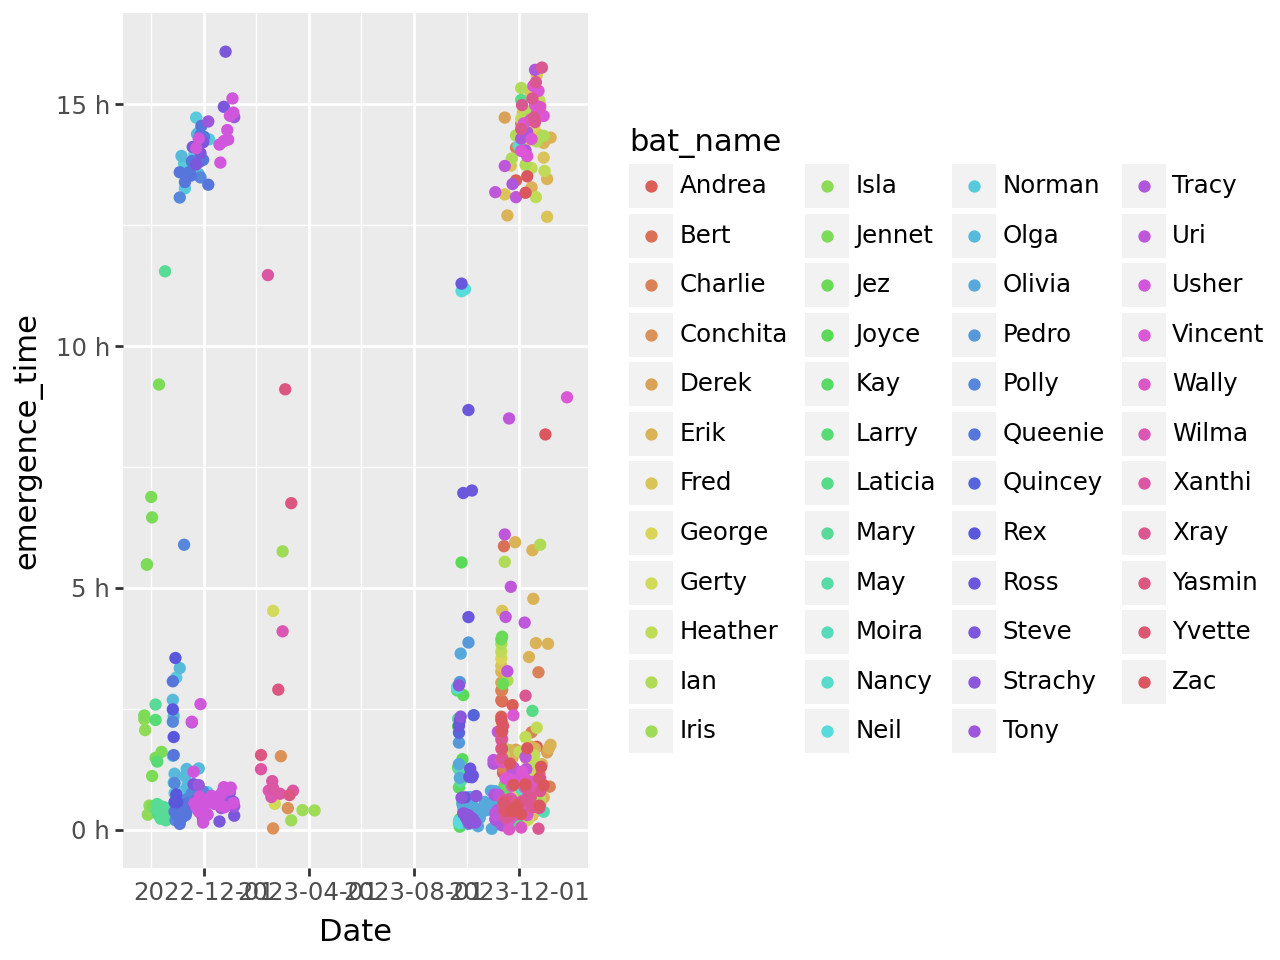

In [17]:
(
    ggplot(first_detection, aes(x="Date", y="emergence_time", colour="bat_name"))
    + geom_point()
)

C:\Users\allan\anaconda3\envs\bat_analysis\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 34'. Pick better value with 'binwidth'.


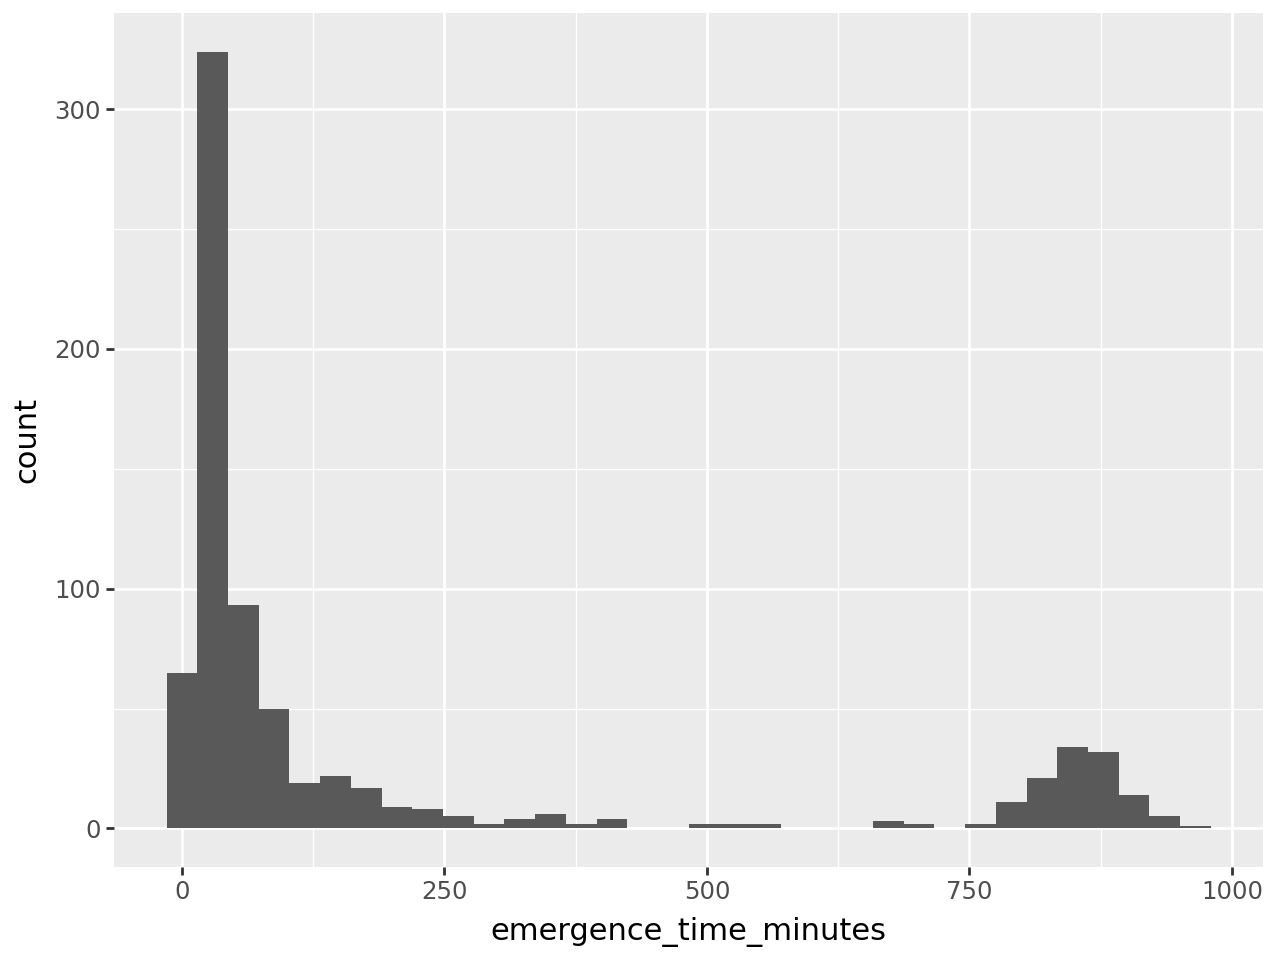

In [18]:
(
    ggplot(first_detection, aes(x="emergence_time_minutes"))
    + geom_histogram()
)

In [19]:
# calculate time since last detection in minutes
last_detection["reentry_time"] = last_detection["sunriseEnd"] - last_detection["time"]
last_detection["reentry_time_minutes"] = last_detection["reentry_time"].dt.total_seconds().div(60)
last_detection

,bat_name,bat_day,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,...,week,n_receivers,activity_class,rec_type,bat_day_next,sunsetStart,sunriseEnd,Date,reentry_time,reentry_time_minutes
0,Andrea,2023-11-10,5,33663378,3781a5,-109.0,2023-11-10 20:50:11+00:00,CFF730D7207F,kl_div,29837.0,...,45,1.0,active,Node,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,0 days 10:36:39,636.650000
1,Andrea,2023-11-11,5,33663378,3292c8,-107.0,2023-11-11 19:40:37+00:00,31D096AEC921,kl_div,8930.0,...,45,1.0,none,Node,2023-11-12,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,2023-11-11,0 days 11:47:56,707.933333
2,Andrea,2023-11-12,4,33663378,37792f,-107.0,2023-11-12 23:16:29+00:00,31D096AEC921,ctt,1563.0,...,45,1.0,none,Station,2023-11-13,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,2023-11-12,0 days 08:13:46,493.766667
3,Andrea,2023-11-13,2,33663378,37792f,-107.0,2023-11-14 05:38:35+00:00,V30B0154C8C9,ctt,8930.0,...,46,1.0,none,Station,2023-11-14,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,2023-11-14,0 days 01:53:22,113.366667
4,Andrea,2023-11-14,4,33663378,3795d0,-105.0,2023-11-15 06:11:10+00:00,31D096AEC921,ctt,29837.0,...,46,1.0,active,Node,2023-11-15,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,2023-11-15,0 days 01:22:29,82.483333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,1,2A615252,3795d0,-108.0,2023-12-11 06:45:58+00:00,31D096AEC921,ctt,2886.0,...,50,1.0,active,Station,2023-12-11,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,2023-12-11,0 days 01:24:45,84.750000
757,Zac,2023-12-24,4,2A615252,328787,-105.0,2023-12-25 02:08:48+00:00,31D096AEC921,ctt,1751.0,...,52,1.0,none,Station,2023-12-25,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,2023-12-25,0 days 06:11:27,371.450000
758,Zac,2023-12-26,1,2A615252,3795d0,-106.0,2023-12-26 20:29:38+00:00,31D096AEC921,ctt,1751.0,...,52,1.0,active,Station,2023-12-27,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,2023-12-26,0 days 11:51:09,711.150000
759,Zac,2023-12-29,5,2A615252,37792f,-103.0,2023-12-30 06:19:32+00:00,V30B0154C8C9,ctt,2859.0,...,52,1.0,none,Station,2023-12-30,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,2023-12-30,0 days 02:01:40,121.666667


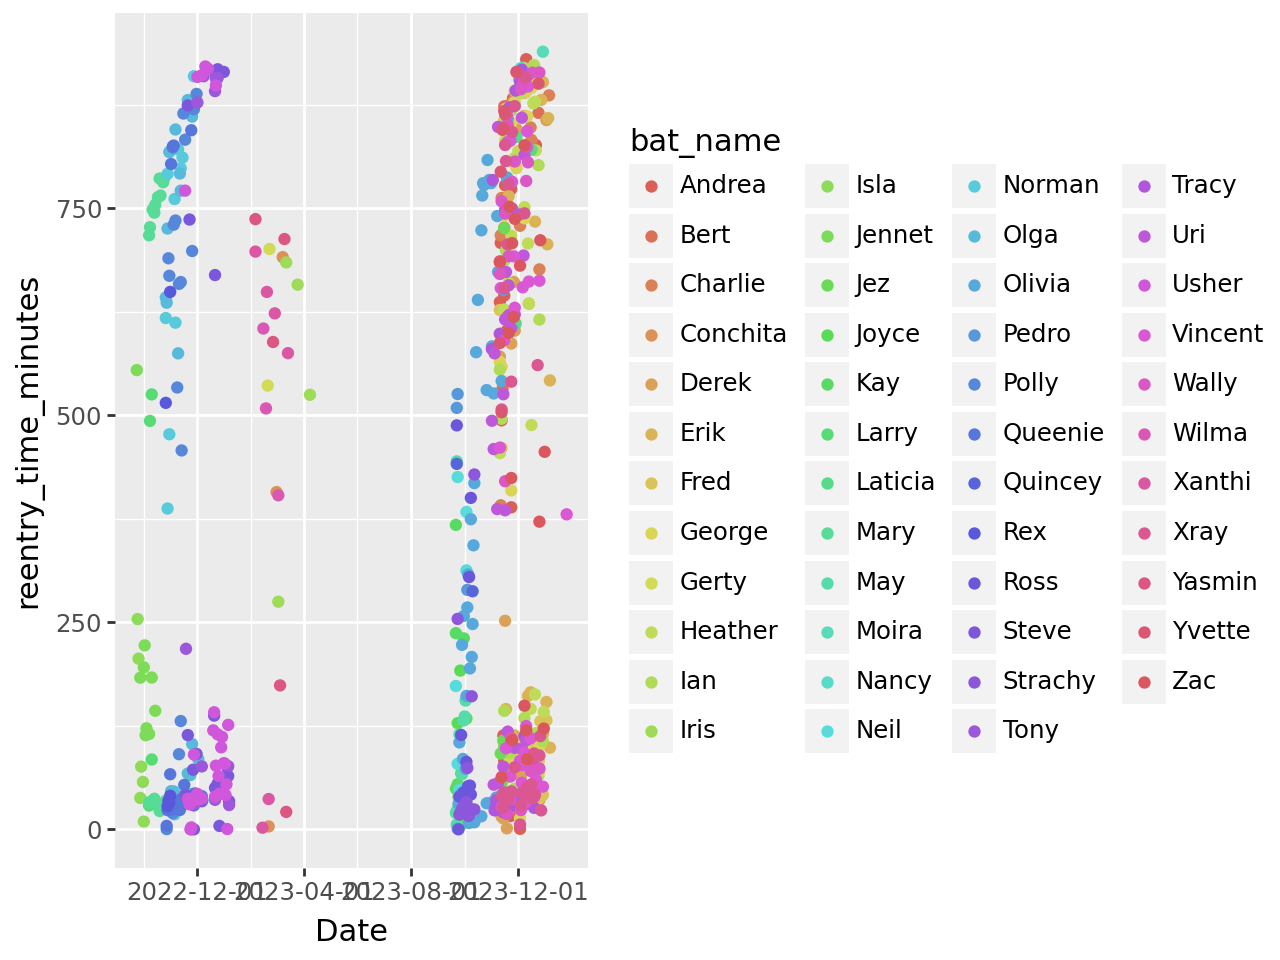

In [20]:
(
    ggplot(last_detection, aes(x="Date", y="reentry_time_minutes", colour="bat_name"))
    + geom_point()
)

C:\Users\allan\anaconda3\envs\bat_analysis\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 7'. Pick better value with 'binwidth'.


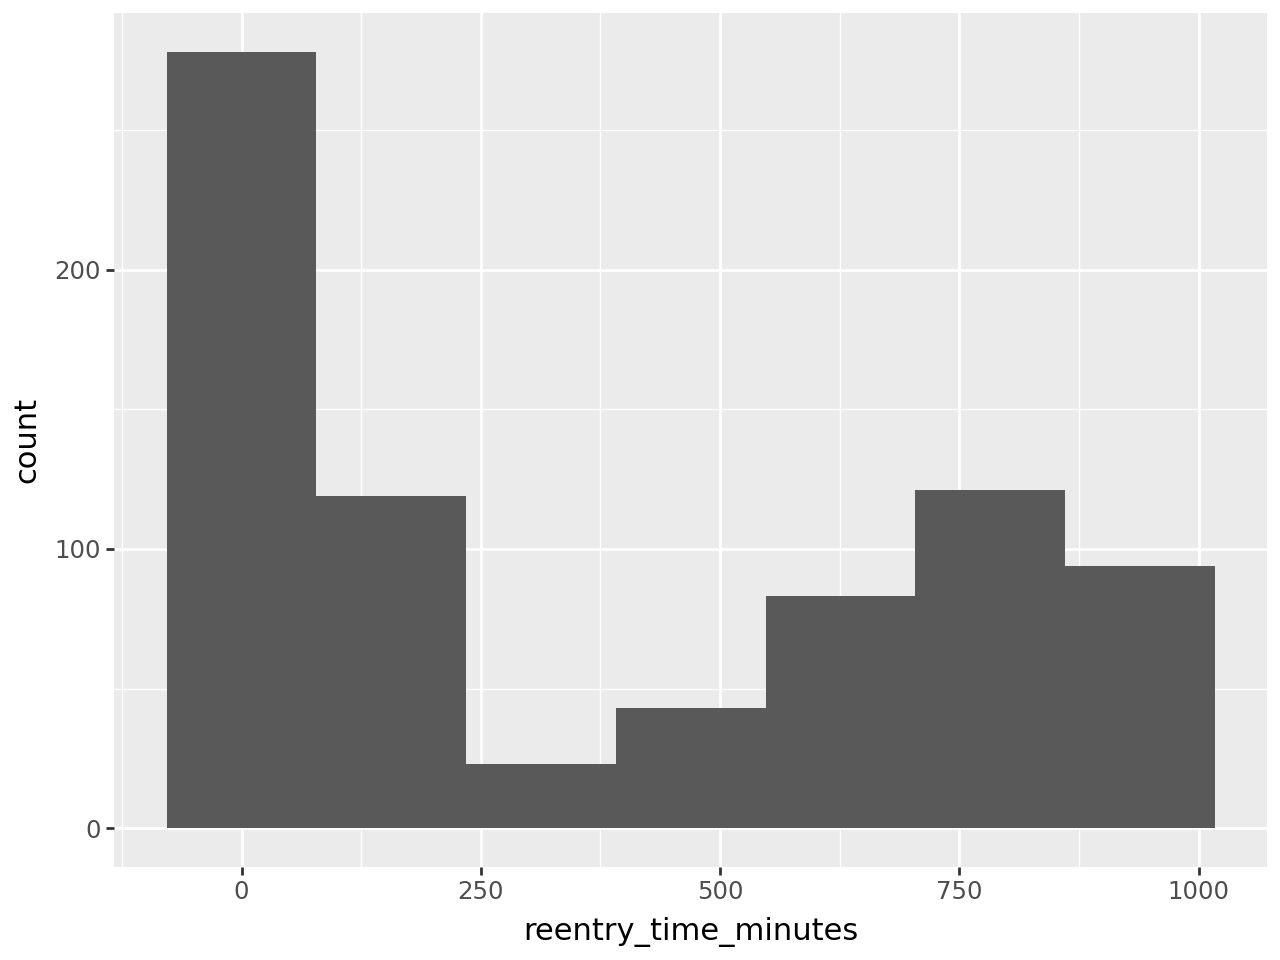

In [21]:
(
    ggplot(last_detection, aes(x="reentry_time_minutes"))
    + geom_histogram()
)

In [22]:
#create new df and round time to minutes
absolute_activity = bat_data
absolute_activity['time_rounded'] = absolute_activity['time'].dt.round(freq='1min')
#remove any duplicated rounded times so that there is one count per minute opf activity
absolute_activity = bat_data.drop_duplicates(['bat_name', 'time_rounded'])
absolute_activity

,radio_id,tag_id,node_id,tag_rssi,time,station_id,method,data_size,median_error_seconds,max_error_seconds,...,week,n_receivers,activity_class,rec_type,bat_day,bat_day_next,sunsetStart,sunriseEnd,Date,time_rounded
0,5,33663378,3781a5,-107.0,2023-11-10 18:54:13+00:00,None,kl_div,29837.0,123.0,565.0,...,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 18:54:00+00:00
2,5,33663378,3781a5,-106.0,2023-11-10 18:54:33+00:00,None,kl_div,29837.0,123.0,565.0,...,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 18:55:00+00:00
4,5,33663378,328787,-108.0,2023-11-10 18:56:44+00:00,None,kl_div,7509.0,123.0,565.0,...,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 18:57:00+00:00
6,5,33663378,37807e,-111.0,2023-11-10 18:57:38+00:00,None,kl_div,3584.0,123.0,565.0,...,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 18:58:00+00:00
18,5,33663378,3781a5,-105.0,2023-11-10 18:58:32+00:00,None,kl_div,29837.0,123.0,565.0,...,45,NaN,none,Node,2023-11-10,2023-11-11,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,2023-11-10,2023-11-10 18:59:00+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144367,1,2A615252,None,-108.0,2023-12-31 00:40:26+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31,2023-12-31 00:40:00+00:00
144368,1,2A615252,None,-109.0,2023-12-31 00:41:25+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31,2023-12-31 00:41:00+00:00
144369,1,2A615252,None,-110.0,2023-12-31 00:41:34+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31,2023-12-31 00:42:00+00:00
144371,1,2A615252,None,-106.0,2023-12-31 00:42:33+00:00,31D096AEC921,ctt,NaN,NaN,NaN,...,52,1.0,active,Station,2023-12-30,2023-12-31,2023-12-30 16:14:36+00:00,2023-12-31 08:21:13+00:00,2023-12-31,2023-12-31 00:43:00+00:00


In [23]:
#count the number of active minutes per bat and date
absolute_counts = absolute_activity.sort_values('time').groupby(['bat_name', 'bat_day']).size().reset_index(name='absolute_activity_minutes', drop=False)
absolute_counts

,bat_name,bat_day,absolute_activity_minutes
0,Andrea,2023-11-10,20
1,Andrea,2023-11-11,10
2,Andrea,2023-11-12,160
3,Andrea,2023-11-13,54
4,Andrea,2023-11-14,73
...,...,...,...
756,Zac,2023-12-10,48
757,Zac,2023-12-24,23
758,Zac,2023-12-26,32
759,Zac,2023-12-29,28


In [24]:
absolute_counts_hourly = (absolute_activity.sort_values('time').assign(hourly_time=lambda df: df['time'].dt.floor('h')).groupby(['bat_name', 'hourly_time']).size().reset_index(name='absolute_activity_minutes'))
absolute_counts_hourly

,bat_name,hourly_time,absolute_activity_minutes
0,Andrea,2023-11-10 18:00:00+00:00,6
1,Andrea,2023-11-10 19:00:00+00:00,7
2,Andrea,2023-11-10 20:00:00+00:00,7
3,Andrea,2023-11-11 19:00:00+00:00,10
4,Andrea,2023-11-12 17:00:00+00:00,13
...,...,...,...
2624,Zac,2023-12-26 20:00:00+00:00,10
2625,Zac,2023-12-29 17:00:00+00:00,9
2626,Zac,2023-12-29 18:00:00+00:00,10
2627,Zac,2023-12-30 06:00:00+00:00,9


In [25]:
#calculate the night length and round to minute intervals
sun_data['night_length'] = sun_data["sunriseEnd"] - sun_data["sunsetStart"]
sun_data["night_length"] = sun_data["night_length"].dt.total_seconds().div(60)
sun_data['night_length_rounded'] = sun_data['night_length'].round()
sun_data

,Date,Next_Date,sunsetStart,sunriseEnd,night_length,night_length_rounded
0,2021-09-13,2021-09-14,2021-09-13 18:31:57+00:00,2021-09-14 05:53:11+00:00,681.233333,681.0
1,2021-09-14,2021-09-15,2021-09-14 18:29:42+00:00,2021-09-15 05:54:41+00:00,684.983333,685.0
2,2021-09-15,2021-09-16,2021-09-15 18:27:27+00:00,2021-09-16 05:56:12+00:00,688.750000,689.0
3,2021-09-16,2021-09-17,2021-09-16 18:25:12+00:00,2021-09-17 05:57:44+00:00,692.533333,693.0
4,2021-09-17,2021-09-18,2021-09-17 18:22:57+00:00,2021-09-18 05:59:15+00:00,696.300000,696.0
...,...,...,...,...,...,...
860,2024-01-21,2024-01-22,2024-01-21 16:43:31+00:00,2024-01-22 08:08:46+00:00,925.250000,925.0
861,2024-01-22,2024-01-23,2024-01-22 16:45:09+00:00,2024-01-23 08:07:39+00:00,922.500000,922.0
862,2024-01-23,2024-01-24,2024-01-23 16:46:49+00:00,2024-01-24 08:06:31+00:00,919.700000,920.0
863,2024-01-24,2024-01-25,2024-01-24 16:48:30+00:00,2024-01-25 08:05:20+00:00,916.833333,917.0


In [26]:
#join the sun_data to the absolute counts then calculate the proportion of active time
absolute_counts = pd.merge(left = absolute_counts,
                           right = sun_data[['Date', 'night_length', 'night_length_rounded']],
                           how = 'left',
                           left_on = ['bat_day'],
                           right_on = ['Date'])
#calculate the absolute activity as proportion
absolute_counts['absolute_activity_proportion'] = absolute_counts["absolute_activity_minutes"] / absolute_counts["night_length_rounded"]
absolute_counts = absolute_counts.drop(['Date'], axis=1)
absolute_counts

,bat_name,bat_day,absolute_activity_minutes,night_length,night_length_rounded,absolute_activity_proportion
0,Andrea,2023-11-10,20,892.616667,893.0,0.022396
1,Andrea,2023-11-11,10,895.816667,896.0,0.011161
2,Andrea,2023-11-12,160,898.983333,899.0,0.177976
3,Andrea,2023-11-13,54,902.100000,902.0,0.059867
4,Andrea,2023-11-14,73,905.183333,905.0,0.080663
...,...,...,...,...,...,...
756,Zac,2023-12-10,48,963.450000,963.0,0.049844
757,Zac,2023-12-24,23,970.083333,970.0,0.023711
758,Zac,2023-12-26,32,969.333333,969.0,0.033024
759,Zac,2023-12-29,28,967.466667,967.0,0.028956


In [27]:
#select only needed columns and join to sun data
total_activity = total_activity[['bat_name', 'bat_day', 'emergence_time', 'reentry_time', 'total_activity_seconds', 'total_activity_minutes']]
total_activity = pd.merge(left = total_activity,
                           right = sun_data[['Date', 'night_length', 'night_length_rounded']],
                           how = 'left',
                           left_on = ['bat_day'],
                           right_on = ['Date'])
#calculate the absolute activity as proportion
total_activity['total_activity_proportion'] = total_activity["total_activity_minutes"] / total_activity["night_length"]
total_activity = total_activity.drop(['Date', 'total_activity_seconds'], axis=1)
total_activity

,bat_name,bat_day,emergence_time,reentry_time,total_activity_minutes,night_length,night_length_rounded,total_activity_proportion
0,Andrea,2023-11-10,2023-11-10 18:54:13+00:00,2023-11-10 20:50:11+00:00,115.966667,892.616667,893.0,0.129918
1,Andrea,2023-11-11,2023-11-11 19:11:48+00:00,2023-11-11 19:40:37+00:00,28.816667,895.816667,896.0,0.032168
2,Andrea,2023-11-12,2023-11-12 17:41:47+00:00,2023-11-12 23:16:29+00:00,334.700000,898.983333,899.0,0.372309
3,Andrea,2023-11-13,2023-11-13 17:04:03+00:00,2023-11-14 05:38:35+00:00,754.533333,902.100000,902.0,0.836419
4,Andrea,2023-11-14,2023-11-14 16:58:56+00:00,2023-11-15 06:11:10+00:00,792.233333,905.183333,905.0,0.875219
...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,2023-12-10 17:48:05+00:00,2023-12-11 06:45:58+00:00,777.883333,963.450000,963.0,0.807394
757,Zac,2023-12-24,2023-12-24 16:39:57+00:00,2023-12-25 02:08:48+00:00,568.850000,970.083333,970.0,0.586393
758,Zac,2023-12-26,2023-12-26 17:29:15+00:00,2023-12-26 20:29:38+00:00,180.383333,969.333333,969.0,0.186090
759,Zac,2023-12-29,2023-12-29 17:08:44+00:00,2023-12-30 06:19:32+00:00,790.800000,967.466667,967.0,0.817393


In [28]:
#merge total active and absolute counts into one dataframe
bat_metrics = pd.merge(left = total_activity,
                           right = absolute_counts[['bat_name', 'bat_day', 'absolute_activity_minutes', 'absolute_activity_proportion']],
                           how = 'left',
                           left_on = ['bat_name', 'bat_day'],
                           right_on = ['bat_name', 'bat_day'])
bat_metrics

,bat_name,bat_day,emergence_time,reentry_time,total_activity_minutes,night_length,night_length_rounded,total_activity_proportion,absolute_activity_minutes,absolute_activity_proportion
0,Andrea,2023-11-10,2023-11-10 18:54:13+00:00,2023-11-10 20:50:11+00:00,115.966667,892.616667,893.0,0.129918,20,0.022396
1,Andrea,2023-11-11,2023-11-11 19:11:48+00:00,2023-11-11 19:40:37+00:00,28.816667,895.816667,896.0,0.032168,10,0.011161
2,Andrea,2023-11-12,2023-11-12 17:41:47+00:00,2023-11-12 23:16:29+00:00,334.700000,898.983333,899.0,0.372309,160,0.177976
3,Andrea,2023-11-13,2023-11-13 17:04:03+00:00,2023-11-14 05:38:35+00:00,754.533333,902.100000,902.0,0.836419,54,0.059867
4,Andrea,2023-11-14,2023-11-14 16:58:56+00:00,2023-11-15 06:11:10+00:00,792.233333,905.183333,905.0,0.875219,73,0.080663
...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,2023-12-10 17:48:05+00:00,2023-12-11 06:45:58+00:00,777.883333,963.450000,963.0,0.807394,48,0.049844
757,Zac,2023-12-24,2023-12-24 16:39:57+00:00,2023-12-25 02:08:48+00:00,568.850000,970.083333,970.0,0.586393,23,0.023711
758,Zac,2023-12-26,2023-12-26 17:29:15+00:00,2023-12-26 20:29:38+00:00,180.383333,969.333333,969.0,0.186090,32,0.033024
759,Zac,2023-12-29,2023-12-29 17:08:44+00:00,2023-12-30 06:19:32+00:00,790.800000,967.466667,967.0,0.817393,28,0.028956


In [29]:
#merge first detection into dataframe
bat_metrics = pd.merge(left = bat_metrics,
                           right = first_detection[['bat_name', 'bat_day', 'sunsetStart', 'sunriseEnd', 'emergence_time_minutes']],
                           how = 'left',
                           left_on = ['bat_name', 'bat_day'],
                           right_on = ['bat_name', 'bat_day'])
bat_metrics

,bat_name,bat_day,emergence_time,reentry_time,total_activity_minutes,night_length,night_length_rounded,total_activity_proportion,absolute_activity_minutes,absolute_activity_proportion,sunsetStart,sunriseEnd,emergence_time_minutes
0,Andrea,2023-11-10,2023-11-10 18:54:13+00:00,2023-11-10 20:50:11+00:00,115.966667,892.616667,893.0,0.129918,20,0.022396,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,140.000000
1,Andrea,2023-11-11,2023-11-11 19:11:48+00:00,2023-11-11 19:40:37+00:00,28.816667,895.816667,896.0,0.032168,10,0.011161,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,159.066667
2,Andrea,2023-11-12,2023-11-12 17:41:47+00:00,2023-11-12 23:16:29+00:00,334.700000,898.983333,899.0,0.372309,160,0.177976,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,70.516667
3,Andrea,2023-11-13,2023-11-13 17:04:03+00:00,2023-11-14 05:38:35+00:00,754.533333,902.100000,902.0,0.836419,54,0.059867,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,34.200000
4,Andrea,2023-11-14,2023-11-14 16:58:56+00:00,2023-11-15 06:11:10+00:00,792.233333,905.183333,905.0,0.875219,73,0.080663,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,30.466667
...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,2023-12-10 17:48:05+00:00,2023-12-11 06:45:58+00:00,777.883333,963.450000,963.0,0.807394,48,0.049844,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,100.816667
757,Zac,2023-12-24,2023-12-24 16:39:57+00:00,2023-12-25 02:08:48+00:00,568.850000,970.083333,970.0,0.586393,23,0.023711,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,29.783333
758,Zac,2023-12-26,2023-12-26 17:29:15+00:00,2023-12-26 20:29:38+00:00,180.383333,969.333333,969.0,0.186090,32,0.033024,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,77.800000
759,Zac,2023-12-29,2023-12-29 17:08:44+00:00,2023-12-30 06:19:32+00:00,790.800000,967.466667,967.0,0.817393,28,0.028956,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,55.000000


In [30]:
#merge last detection into dataframe
bat_metrics = pd.merge(left = bat_metrics,
                           right = last_detection[['bat_name', 'bat_day', 'reentry_time_minutes']],
                           how = 'left',
                           left_on = ['bat_name', 'bat_day'],
                           right_on = ['bat_name', 'bat_day'])
bat_metrics

,bat_name,bat_day,emergence_time,reentry_time,total_activity_minutes,night_length,night_length_rounded,total_activity_proportion,absolute_activity_minutes,absolute_activity_proportion,sunsetStart,sunriseEnd,emergence_time_minutes,reentry_time_minutes
0,Andrea,2023-11-10,2023-11-10 18:54:13+00:00,2023-11-10 20:50:11+00:00,115.966667,892.616667,893.0,0.129918,20,0.022396,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,140.000000,636.650000
1,Andrea,2023-11-11,2023-11-11 19:11:48+00:00,2023-11-11 19:40:37+00:00,28.816667,895.816667,896.0,0.032168,10,0.011161,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,159.066667,707.933333
2,Andrea,2023-11-12,2023-11-12 17:41:47+00:00,2023-11-12 23:16:29+00:00,334.700000,898.983333,899.0,0.372309,160,0.177976,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,70.516667,493.766667
3,Andrea,2023-11-13,2023-11-13 17:04:03+00:00,2023-11-14 05:38:35+00:00,754.533333,902.100000,902.0,0.836419,54,0.059867,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,34.200000,113.366667
4,Andrea,2023-11-14,2023-11-14 16:58:56+00:00,2023-11-15 06:11:10+00:00,792.233333,905.183333,905.0,0.875219,73,0.080663,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,30.466667,82.483333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,2023-12-10 17:48:05+00:00,2023-12-11 06:45:58+00:00,777.883333,963.450000,963.0,0.807394,48,0.049844,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,100.816667,84.750000
757,Zac,2023-12-24,2023-12-24 16:39:57+00:00,2023-12-25 02:08:48+00:00,568.850000,970.083333,970.0,0.586393,23,0.023711,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,29.783333,371.450000
758,Zac,2023-12-26,2023-12-26 17:29:15+00:00,2023-12-26 20:29:38+00:00,180.383333,969.333333,969.0,0.186090,32,0.033024,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,77.800000,711.150000
759,Zac,2023-12-29,2023-12-29 17:08:44+00:00,2023-12-30 06:19:32+00:00,790.800000,967.466667,967.0,0.817393,28,0.028956,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,55.000000,121.666667


In [31]:
#rename columns
bat_metrics = bat_metrics.loc[:, ['bat_name', 'bat_day', 'sunsetStart', 'sunriseEnd', 'night_length', 'night_length_rounded', 'emergence_time', 'emergence_time_minutes', 'reentry_time', 'reentry_time_minutes', 'total_activity_minutes', 'total_activity_proportion', 'absolute_activity_minutes', 'absolute_activity_proportion']]
bat_metrics

,bat_name,bat_day,sunsetStart,sunriseEnd,night_length,night_length_rounded,emergence_time,emergence_time_minutes,reentry_time,reentry_time_minutes,total_activity_minutes,total_activity_proportion,absolute_activity_minutes,absolute_activity_proportion
0,Andrea,2023-11-10,2023-11-10 16:34:13+00:00,2023-11-11 07:26:50+00:00,892.616667,893.0,2023-11-10 18:54:13+00:00,140.000000,2023-11-10 20:50:11+00:00,636.650000,115.966667,0.129918,20,0.022396
1,Andrea,2023-11-11,2023-11-11 16:32:44+00:00,2023-11-12 07:28:33+00:00,895.816667,896.0,2023-11-11 19:11:48+00:00,159.066667,2023-11-11 19:40:37+00:00,707.933333,28.816667,0.032168,10,0.011161
2,Andrea,2023-11-12,2023-11-12 16:31:16+00:00,2023-11-13 07:30:15+00:00,898.983333,899.0,2023-11-12 17:41:47+00:00,70.516667,2023-11-12 23:16:29+00:00,493.766667,334.700000,0.372309,160,0.177976
3,Andrea,2023-11-13,2023-11-13 16:29:51+00:00,2023-11-14 07:31:57+00:00,902.100000,902.0,2023-11-13 17:04:03+00:00,34.200000,2023-11-14 05:38:35+00:00,113.366667,754.533333,0.836419,54,0.059867
4,Andrea,2023-11-14,2023-11-14 16:28:28+00:00,2023-11-15 07:33:39+00:00,905.183333,905.0,2023-11-14 16:58:56+00:00,30.466667,2023-11-15 06:11:10+00:00,82.483333,792.233333,0.875219,73,0.080663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,Zac,2023-12-10,2023-12-10 16:07:16+00:00,2023-12-11 08:10:43+00:00,963.450000,963.0,2023-12-10 17:48:05+00:00,100.816667,2023-12-11 06:45:58+00:00,84.750000,777.883333,0.807394,48,0.049844
757,Zac,2023-12-24,2023-12-24 16:10:10+00:00,2023-12-25 08:20:15+00:00,970.083333,970.0,2023-12-24 16:39:57+00:00,29.783333,2023-12-25 02:08:48+00:00,371.450000,568.850000,0.586393,23,0.023711
758,Zac,2023-12-26,2023-12-26 16:11:27+00:00,2023-12-27 08:20:47+00:00,969.333333,969.0,2023-12-26 17:29:15+00:00,77.800000,2023-12-26 20:29:38+00:00,711.150000,180.383333,0.186090,32,0.033024
759,Zac,2023-12-29,2023-12-29 16:13:44+00:00,2023-12-30 08:21:12+00:00,967.466667,967.0,2023-12-29 17:08:44+00:00,55.000000,2023-12-30 06:19:32+00:00,121.666667,790.800000,0.817393,28,0.028956


## Export data

In [ ]:
#export data to csv file
bat_metrics.to_csv('output/bat_data_filtered_class_join_red_night_metrics.csv', index=False)
absolute_counts_hourly.to_csv('output/bat_data_filtered_class_join_red_night_hourly_count.csv', index=False)


761